In [1]:
import sys, pandas, seaborn
print(sys.executable)
print(pandas.__version__, seaborn.__version__)

c:\Users\user\Desktop\Ingenieria informatica\6 Semestre\Estadistica y probabilidad para inteligencia de negocios\Analisis Exploratorio y Visualizacion de Datos\venv\Scripts\python.exe
3.1.1 0.13.2


In [2]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')

In [3]:
try:
    import kagglehub
    path = kagglehub.dataset_download('parulpandey/palmer-archipelago-antarctica-penguin-data')
    df = pd.read_csv(os.path.join(path, 'penguins_size.csv'))
    df = df.rename(columns={'culmen_length_mm':'bill_length_mm','culmen_depth_mm':'bill_depth_mm'})
    fuente = 'Kaggle'
except Exception as e:
    print('Kaggle no disponible:', type(e).__name__)
    df = sns.load_dataset('penguins')
    fuente = 'seaborn (respaldo)'
df.to_csv('data/penguins.csv', index=False)
print('Fuente:', fuente, '| shape:', df.shape)
df.head()

Fuente: Kaggle | shape: (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [4]:
df.info()
print(df.isna().sum())
print('Duplicados:', df.duplicated().sum())
for c in ['species','island','sex']:
    print(df[c].value_counts(dropna=False), '\n')

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                334 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  10
dtype: int64
Duplicados: 0
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64 

island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64 

sex
MALE      168
FEMALE    165
NaN        10
.           1
Name: count, dtype: int64 



In [5]:
df['sex'] = df['sex'].replace('.', np.nan).str.capitalize()
num = ['bill_length_mm','bill_depth_mm','flipper_length_mm','body_mass_g']
df[num] = df.groupby('species')[num].transform(lambda s: s.fillna(s.median()))
df.isna().sum()

species               0
island                0
bill_length_mm        0
bill_depth_mm         0
flipper_length_mm     0
body_mass_g           0
sex                  11
dtype: int64

In [6]:
df[num].describe().T

,count,mean,std,min,25%,50%,75%,max
bill_length_mm,344.0,43.916860,5.453713,32.1,39.200,44.45,48.50,59.6
bill_depth_mm,344.0,17.148547,1.973601,13.1,15.575,17.30,18.70,21.5
flipper_length_mm,344.0,200.927326,14.056652,172.0,190.000,197.00,213.25,231.0
body_mass_g,344.0,4202.616279,801.231551,2700.0,3550.000,4050.00,4756.25,6300.0


In [7]:
est = df[num].agg(['mean','median','var','std','min','max','skew','kurt']).T
est['CV_%'] = est['std']/est['mean']*100
est['rango'] = est['max']-est['min']
est.round(2)

,mean,median,var,std,min,max,skew,kurt,CV_%,rango
bill_length_mm,43.92,44.45,29.74,5.45,32.1,59.6,0.05,-0.88,12.42,27.5
bill_depth_mm,17.15,17.30,3.90,1.97,13.1,21.5,-0.14,-0.91,11.51,8.4
flipper_length_mm,200.93,197.00,197.59,14.06,172.0,231.0,0.34,-0.99,7.00,59.0
body_mass_g,4202.62,4050.00,641972.00,801.23,2700.0,6300.0,0.47,-0.72,19.07,3600.0


In [8]:
df.groupby('species')[num].agg(['mean','std','var']).round(2).T

species                    Adelie  Chinstrap     Gentoo
bill_length_mm    mean      38.79      48.83      47.50
                  std        2.65       3.34       3.07
                  var        7.05      11.15       9.42
bill_depth_mm     mean      18.35      18.42      14.98
                  std        1.21       1.14       0.98
                  var        1.47       1.29       0.95
flipper_length_mm mean     189.95     195.82     217.18
                  std        6.52       7.13       6.46
                  var       42.48      50.86      41.72
body_mass_g       mean    3700.66    3733.09    5075.40
                  std      457.05     384.34     502.11
                  var   208890.29  147713.45  252113.66

In [9]:
df[num].corr().round(2)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.00,-0.24,0.66,0.60
bill_depth_mm,-0.24,1.00,-0.59,-0.47
flipper_length_mm,0.66,-0.59,1.00,0.87
body_mass_g,0.60,-0.47,0.87,1.00


In [10]:
df.groupby('species')[num].agg(['mean','std','var']).round(2).T

species                    Adelie  Chinstrap     Gentoo
bill_length_mm    mean      38.79      48.83      47.50
                  std        2.65       3.34       3.07
                  var        7.05      11.15       9.42
bill_depth_mm     mean      18.35      18.42      14.98
                  std        1.21       1.14       0.98
                  var        1.47       1.29       0.95
flipper_length_mm mean     189.95     195.82     217.18
                  std        6.52       7.13       6.46
                  var       42.48      50.86      41.72
body_mass_g       mean    3700.66    3733.09    5075.40
                  std      457.05     384.34     502.11
                  var   208890.29  147713.45  252113.66

In [11]:
df[num].corr().round(2)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.00,-0.24,0.66,0.60
bill_depth_mm,-0.24,1.00,-0.59,-0.47
flipper_length_mm,0.66,-0.59,1.00,0.87
body_mass_g,0.60,-0.47,0.87,1.00


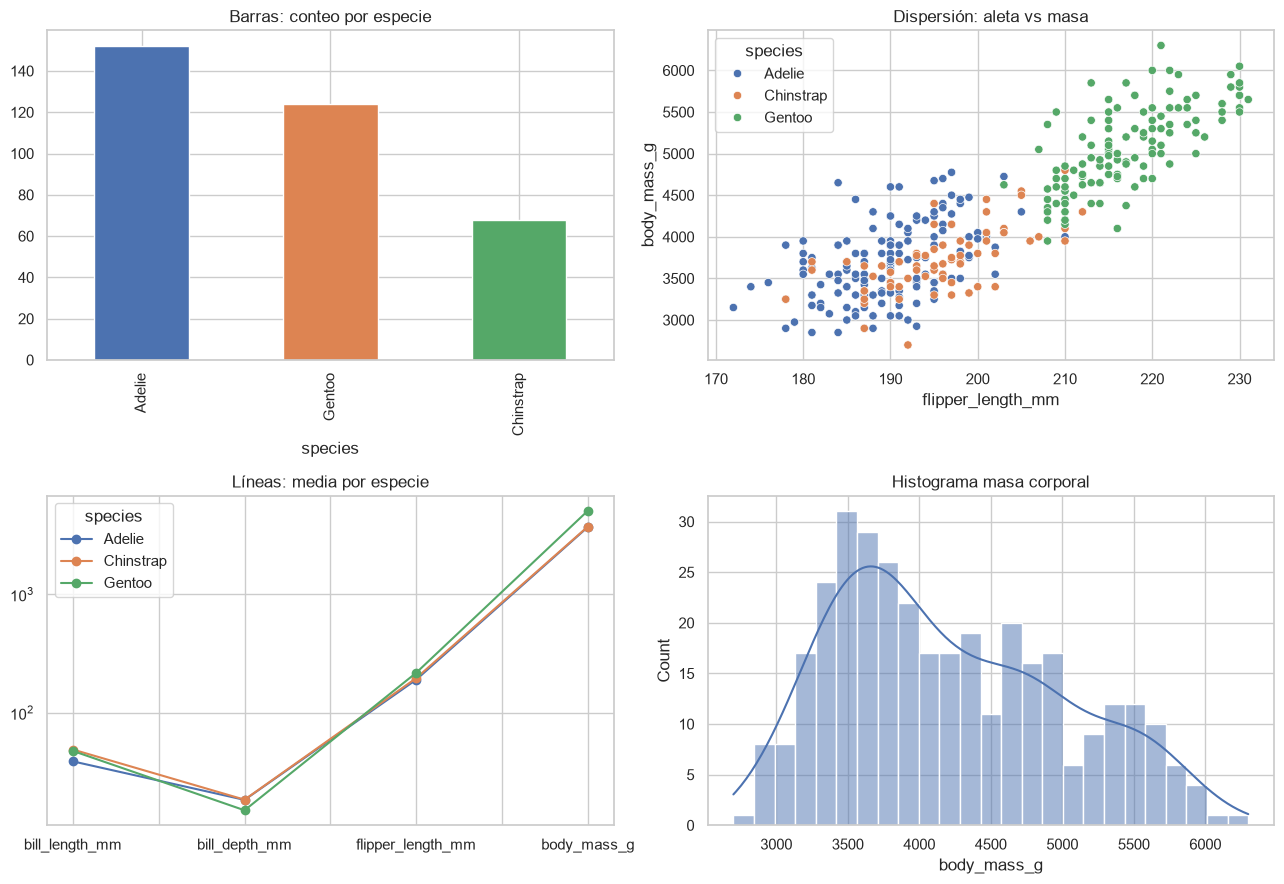

In [12]:
fig, ax = plt.subplots(2,2, figsize=(13,9))
df['species'].value_counts().plot(kind='bar', ax=ax[0,0], color=sns.color_palette()[:3], title='Barras: conteo por especie')
sns.scatterplot(data=df, x='flipper_length_mm', y='body_mass_g', hue='species', ax=ax[0,1]); ax[0,1].set_title('Dispersión: aleta vs masa')
df.groupby('species')[num].mean().T.plot(ax=ax[1,0], marker='o', title='Líneas: media por especie'); ax[1,0].set_yscale('log')
sns.histplot(df['body_mass_g'], bins=25, kde=True, ax=ax[1,1]); ax[1,1].set_title('Histograma masa corporal')
plt.tight_layout(); plt.savefig('figuras/base.png', dpi=130); plt.show()

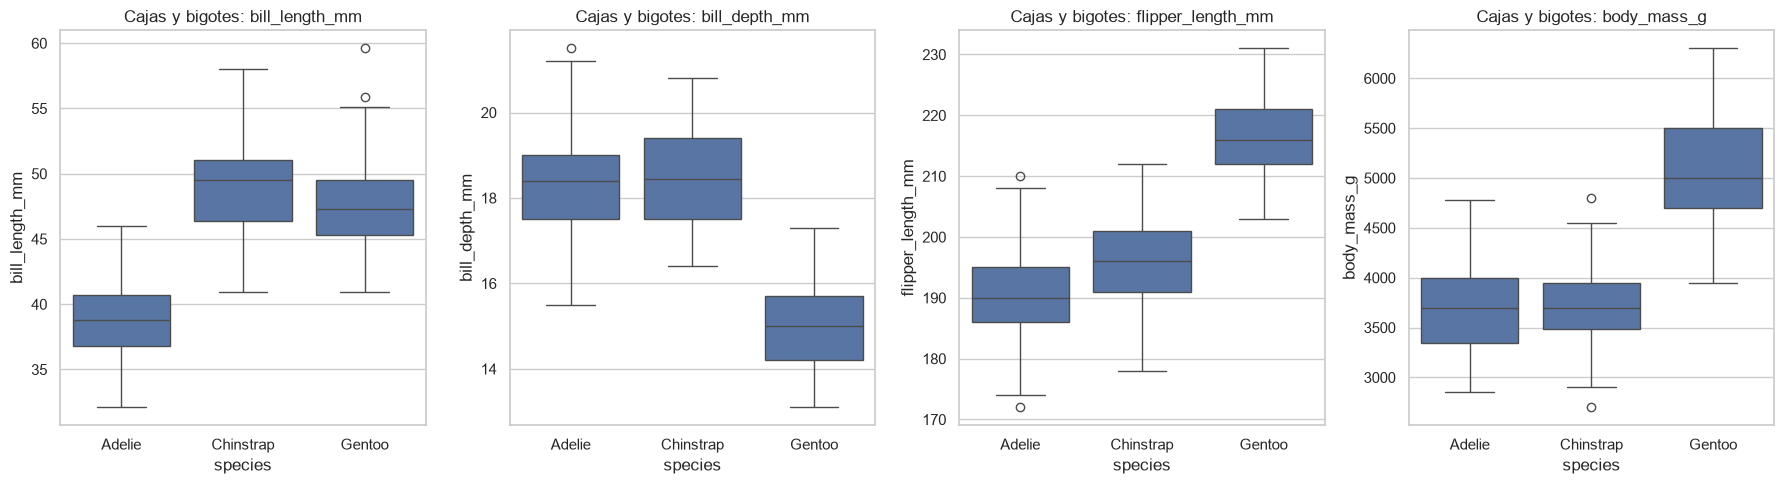

bill_length_mm: 0 outliers
bill_depth_mm: 0 outliers
flipper_length_mm: 0 outliers
body_mass_g: 0 outliers


In [13]:
fig, ax = plt.subplots(1,4, figsize=(18,5))
for a, c in zip(ax, num):
    sns.boxplot(data=df, x='species', y=c, ax=a); a.set_title(f'Cajas y bigotes: {c}')
plt.tight_layout(); plt.savefig('figuras/boxplots.png', dpi=130); plt.show()

for c in num:
    q1, q3 = df[c].quantile([.25,.75]); i = q3 - q1
    n = ((df[c] < q1-1.5*i) | (df[c] > q3+1.5*i)).sum()
    print(f'{c}: {n} outliers')

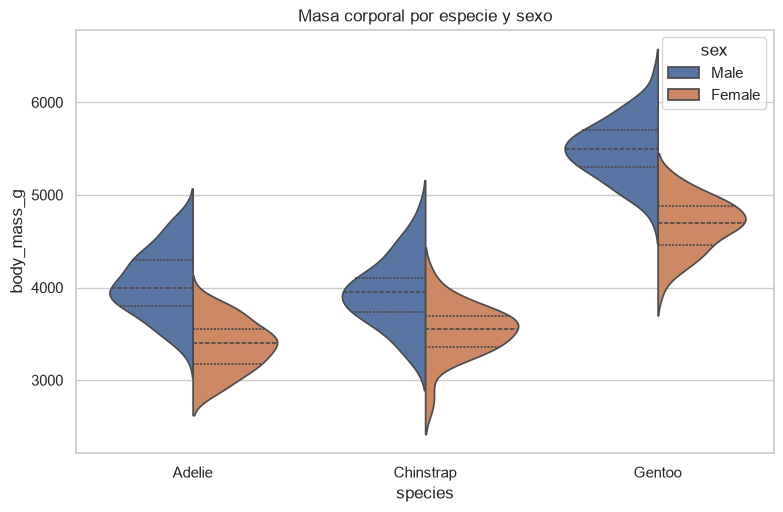

sex        Female    Male
species                  
Adelie     3369.0  4043.0
Chinstrap  3527.0  3939.0
Gentoo     4680.0  5485.0


In [14]:
d = df.dropna(subset=['sex'])
plt.figure(figsize=(9,5.5))
sns.violinplot(data=d, x='species', y='body_mass_g', hue='sex', split=True, inner='quart')
plt.title('Masa corporal por especie y sexo')
plt.savefig('figuras/violin.png', dpi=130); plt.show()
print(d.groupby(['species','sex'])['body_mass_g'].mean().round(0).unstack())

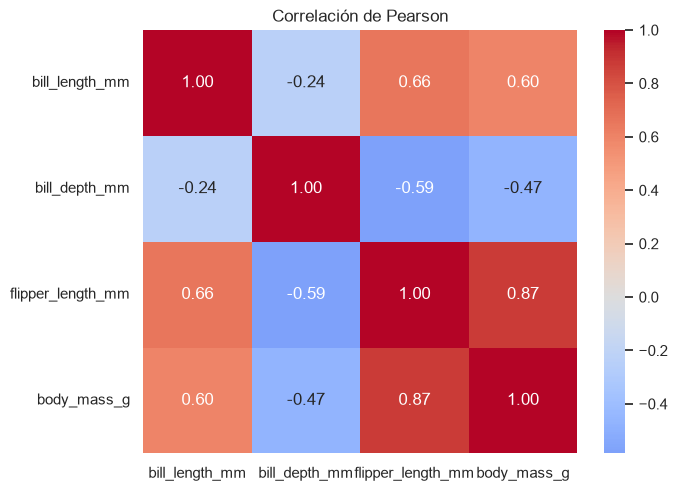

In [15]:
plt.figure(figsize=(7,5.5))
sns.heatmap(df[num].corr(), annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Correlación de Pearson')
plt.savefig('figuras/heatmap.png', dpi=130); plt.show()

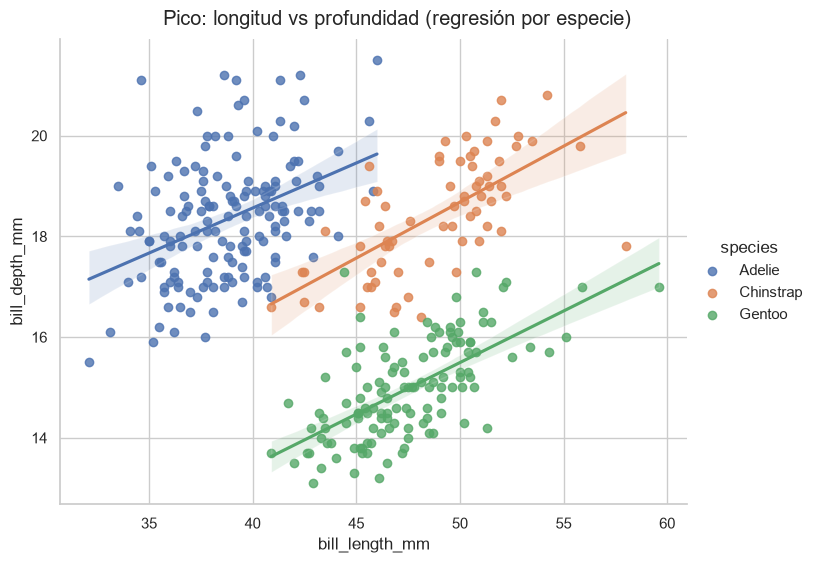

Global r = -0.24
Adelie r = 0.39
Chinstrap r = 0.65
Gentoo r = 0.64


In [16]:
g = sns.lmplot(data=df, x='bill_length_mm', y='bill_depth_mm', hue='species', height=5.5, aspect=1.3)
g.figure.suptitle('Pico: longitud vs profundidad (regresión por especie)', y=1.02)
g.savefig('figuras/simpson.png', dpi=130); plt.show()

print('Global r =', round(df[['bill_length_mm','bill_depth_mm']].corr().iloc[0,1],2))
for s, g_ in df.groupby('species'):
    print(s, 'r =', round(g_[['bill_length_mm','bill_depth_mm']].corr().iloc[0,1],2))

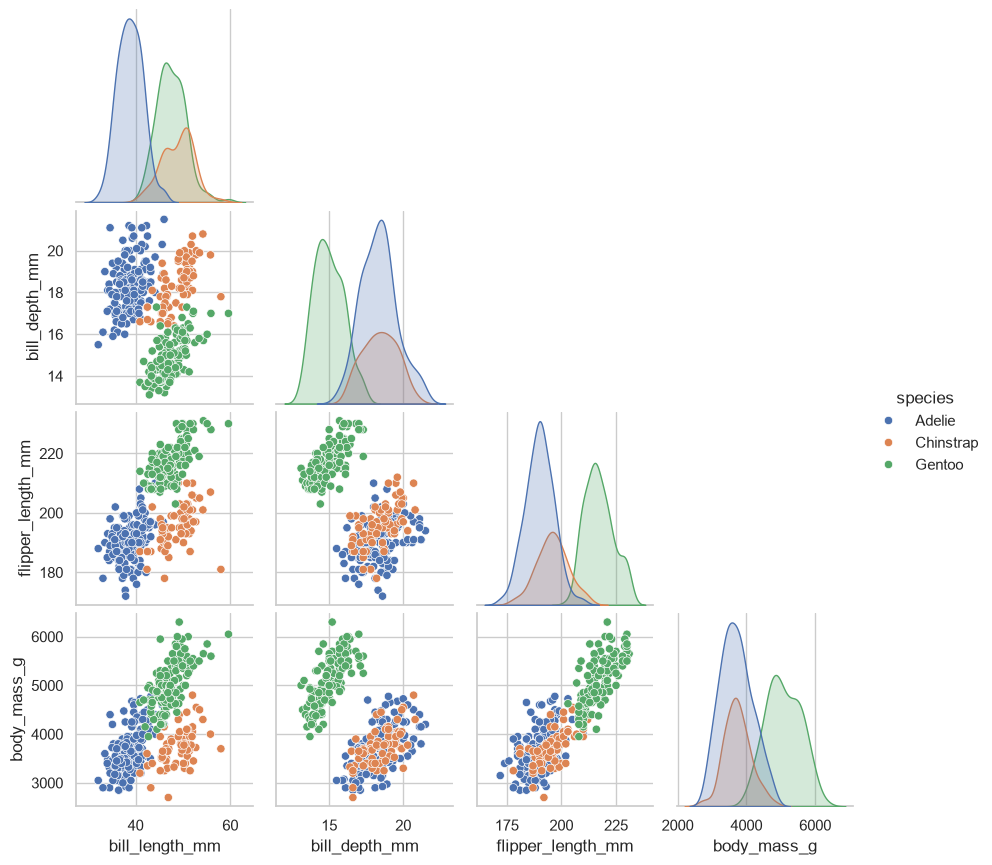

In [17]:
g = sns.pairplot(df, vars=num, hue='species', diag_kind='kde', corner=True, height=2.2)
g.savefig('figuras/pairplot.png', dpi=110); plt.show()

In [18]:
grupos = [g['body_mass_g'] for _, g in df.groupby('species')]
F, p = stats.f_oneway(*grupos)
print(f'ANOVA masa ~ especie: F={F:.1f}, p={p:.2e}')
print('Shapiro por especie:', {s: round(stats.shapiro(g['body_mass_g'])[1],3) for s, g in df.groupby('species')})
print(stats.tukey_hsd(*grupos))

ANOVA masa ~ especie: F=347.7, p=4.86e-83
Shapiro por especie: {'Adelie': np.float64(0.034), 'Chinstrap': np.float64(0.561), 'Gentoo': np.float64(0.257)}
Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)    -32.430     0.880  -190.730   125.869
 (0 - 2)  -1374.745     0.000 -1506.046 -1243.445
 (1 - 0)     32.430     0.880  -125.869   190.730
 (1 - 2)  -1342.315     0.000 -1506.046 -1178.584
 (2 - 0)   1374.745     0.000  1243.445  1506.046
 (2 - 1)   1342.315     0.000  1178.584  1506.046



## Conclusiones
- Gentoo se separa de las otras especies en masa y aleta; Adelie y Chinstrap se distinguen por el pico.
- Hay dimorfismo sexual marcado: los machos pesan más en las tres especies.
- La correlación agregada de `bill_depth_mm` engaña (paradoja de Simpson); conviene analizar por grupo.
- ANOVA y Tukey confirman que Gentoo difiere en masa de las otras dos, y que Adelie y Chinstrap no difieren entre sí.
- Las mejores variables para clasificar especies son `flipper_length_mm`, `bill_length_mm` y `bill_depth_mm`.